# **Oscilador con inversor 74HC04**

## **Simulación**

<img src="esquematico_oscilador_lt.png">

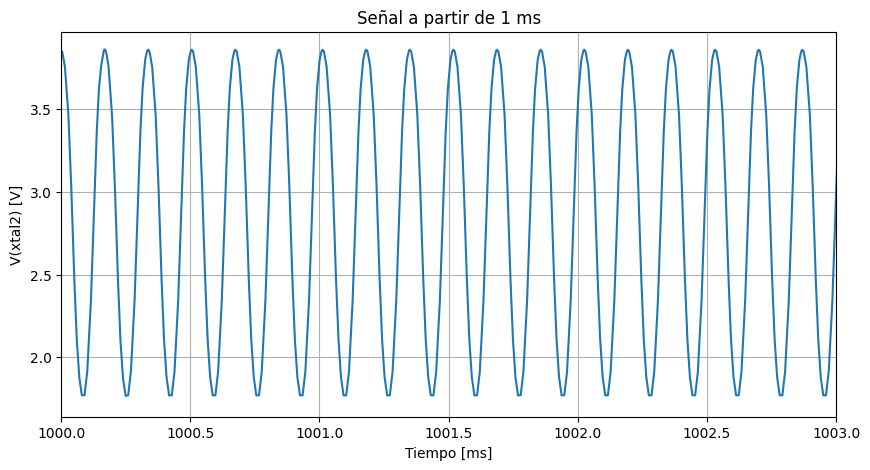

Frecuencia estimada: 5.922816 MHz


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Leer CSV
df = pd.read_csv("oscilador_unit1.csv", sep="\t")

# Quedarse solo con tiempos mayores o iguales a 1 ms
df_filtrado = df[df["time"] >= 1e-3]

# Graficar
plt.figure(figsize=(10,5))
plt.plot(df_filtrado["time"] * 1e6, df_filtrado["V(xtal2)"])
plt.xlim(1000, 1003)

plt.xlabel("Tiempo [ms]")
plt.ylabel("V(xtal2) [V]")
plt.title("Señal a partir de 1 ms")
plt.grid(True)

plt.show()

#============================================================================#
#Código para encontrar la frecuencia de oscilación del cristal#

y = np.asarray(df_filtrado["V(xtal2)"])
t = np.asarray(df_filtrado["time"])

# Buscar cruces por cero con pendiente positiva
crossings = []

for i in range(1, len(y)):

    if y[i-1] < 2.7 and y[i] >= 2.7:
        crossings.append(i)

# Necesitamos al menos 11 cruces
if len(crossings) >= 11:

    i0 = crossings[0]
    i10 = crossings[10]

    t0 = t[i0]
    t10 = t[i10]

    # tiempo total de 10 períodos
    delta_t = t10 - t0

    # frecuencia
    frecuencia = 10 / delta_t

    print(f"Frecuencia estimada: {frecuencia/1e6:.6f} MHz")

else:
    print("No se detectaron suficientes oscilaciones")

## **Mediciones**




### **Oscilador sin buffer de salida**

<img src="osc_sin_buffer.png" width=500>

<img src="osc_salida_cristal.jpeg">

### **Oscilador con buffer de salida**

<img src="oscilador_con_buffer.png" width=800>

<img src="osc_a_la_salida_del_buffer.jpeg">

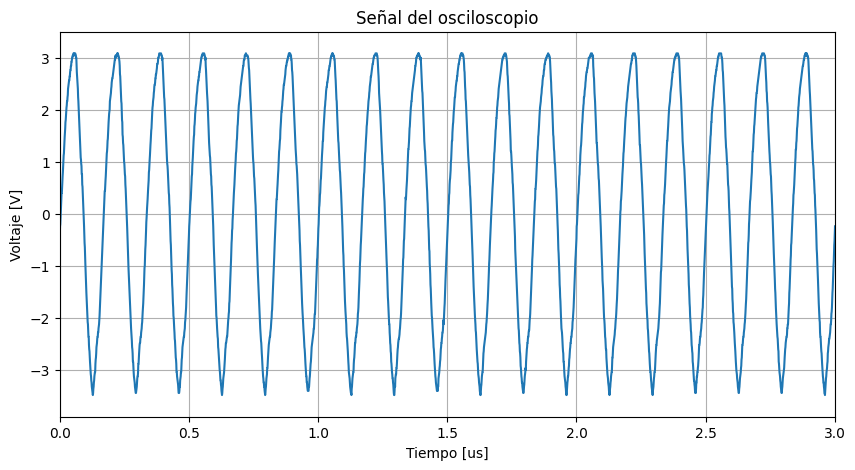

Frecuencia estimada: 6.002401 MHz


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Ruta del archivo CSV/TXT exportado por el osciloscopio
archivo = "osc.csv"

# Leer archivo
with open(archivo, "r") as f:
    lineas = f.readlines()

# Buscar parámetros
time_base = None
sampling_rate = None
datos = []

for linea in lineas:

    linea = linea.strip()

    # Leer Time Base
    if linea.startswith("Time Base:"):
        valor = linea.split(":")[1].strip()

        if "ns" in valor:
            time_base = float(valor.replace("ns", "")) * 1e-9
        elif "us" in valor:
            time_base = float(valor.replace("us", "")) * 1e-6
        elif "ms" in valor:
            time_base = float(valor.replace("ms", "")) * 1e-3

    # Leer Sampling Rate
    elif linea.startswith("Sampling Rate:"):
        valor = linea.split(":")[1].strip()

        if "GSa/s" in valor:
            sampling_rate = float(valor.replace("GSa/s", "")) * 1e9
        elif "MSa/s" in valor:
            sampling_rate = float(valor.replace("MSa/s", "")) * 1e6

    # Leer datos numéricos
    else:
        try:
            datos.append(float(linea))
        except:
            pass

# Convertir a numpy
datos = np.array(datos)

# Crear eje temporal usando sampling rate
dt = 1 / sampling_rate
t = np.arange(len(datos)) * dt

# Graficar
plt.figure(figsize=(10,5))
plt.plot(t * 1e6, datos/1000)
plt.xlim(0, 3)

plt.xlabel("Tiempo [us]")
plt.ylabel("Voltaje [V]")
plt.title("Señal del osciloscopio")
plt.grid(True)

plt.show()


#============================================================================#
#Código para encontrar la frecuencia de oscilación del cristal#

# Convertir mV a V
y = datos / 1000

# Buscar cruces por cero con pendiente positiva
crossings = []

for i in range(1, len(y)):

    if y[i-1] < 0 and y[i] >= 0:
        crossings.append(i)

# Necesitamos al menos 11 cruces
if len(crossings) >= 11:

    i0 = crossings[0]
    i10 = crossings[10]

    t0 = t[i0]
    t10 = t[i10]

    # tiempo total de 10 períodos
    delta_t = t10 - t0

    # frecuencia
    frecuencia = 10 / delta_t

    print(f"Frecuencia estimada: {frecuencia/1e6:.6f} MHz")

else:
    print("No se detectaron suficientes oscilaciones")

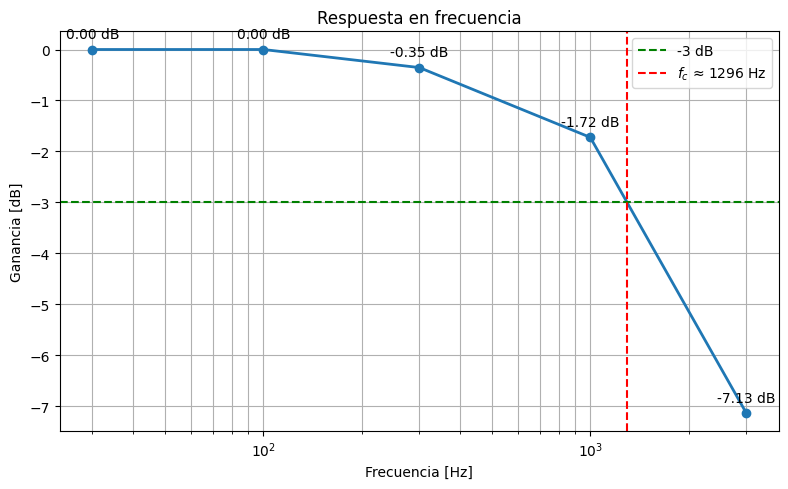

Frecuencia de corte experimental ≈ 1296.0 Hz


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Datos
f = np.array([30, 100, 300, 1000, 3000])  # Hz
Vo = np.array([2.0, 2.0, 1.92, 1.64, 0.88])

Vi = 2.0

H = Vo / Vi
H_dB = 20*np.log10(H)

# Interpolación en escala logarítmica
logf = np.log10(f)

# Buscar cruce con -3 dB
fc_exp = 10**np.interp(-3, H_dB[::-1], logf[::-1])

plt.figure(figsize=(8,5))

plt.semilogx(f, H_dB, 'o-', linewidth=2)

# Etiquetas
for x, y in zip(f, H_dB):
    plt.annotate(f'{y:.2f} dB',
                 (x, y),
                 textcoords="offset points",
                 xytext=(0, 8),
                 ha='center')

# Línea de -3 dB
plt.axhline(-3, color='green', linestyle='--', label='-3 dB')

# Frecuencia de corte experimental
plt.axvline(fc_exp, color='red', linestyle='--',
            label=f'$f_c$ ≈ {fc_exp:.0f} Hz')

plt.grid(True, which='both')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Ganancia [dB]')
plt.title('Respuesta en frecuencia')
plt.legend()

plt.tight_layout()
plt.show()

print(f"Frecuencia de corte experimental ≈ {fc_exp:.1f} Hz")